In [1]:
import os
import tarfile
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import optuna
from tqdm import tqdm

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
QUICK_TEST = False  

TAR_PATH = "data/cifar-100-python.tar.gz"
CKPT_DIR = "checkpoints"
SEED = 42
NUM_CLASSES = 100
DUMMY_ACC = 100.0 / NUM_CLASSES        

EPOCHS = 100   
PATIENCE = 20      
BASELINE = dict(lr=1e-3, weight_decay=1e-4, dropout_rate=0.3, batch_size=64)
LOGREG = dict(lr=1e-2, weight_decay=1e-4, batch_size=64)

N_TRIALS = 50
N_EPOCHS = 20         
BATCH_SIZES = [32, 64, 128]
EVAL_BATCH_SIZE = 1024

if QUICK_TEST:
    EPOCHS, PATIENCE, N_TRIALS, N_EPOCHS = 2, 2, 2, 2
    CKPT_DIR = "checkpoints_quick"

# ----------------------------- Setup ------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"                          # fp16 autocast + GradScaler on GPU only
ACT_DTYPE = torch.float16 if USE_AMP else torch.float32  # dtype of the pre-normalized input tensors

MEAN = torch.tensor((0.5071, 0.4867, 0.4408), device=device).view(1, 3, 1, 1)
STD = torch.tensor((0.2675, 0.2565, 0.2761), device=device).view(1, 3, 1, 1)

torch.backends.cudnn.benchmark = True
torch.manual_seed(SEED)
np.random.seed(SEED)
os.makedirs(CKPT_DIR, exist_ok=True)
print(f"Using device: {device} | AMP: {USE_AMP} | quick test: {QUICK_TEST}")

Using device: cuda | AMP: True | quick test: False


## GPU data utilities

In [3]:
def normalize(x_u8):
    """uint8 (B, 3, H, W) -> normalized float32, channels_last."""
    x = (x_u8.float().div_(255) - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)


def augment_batch(x_u8, padding=4):
    """RandomCrop(32, padding=4) + RandomHorizontalFlip, independently per sample, on the GPU.
    Pads with zeros *before* normalization, exactly like the torchvision pipeline."""
    B, C, H, W = x_u8.shape
    dev = x_u8.device
    x = F.pad(x_u8, (padding,) * 4)
    i = torch.randint(0, 2 * padding + 1, (B,), device=dev)
    j = torch.randint(0, 2 * padding + 1, (B,), device=dev)
    rows = (i[:, None] + torch.arange(H, device=dev))[:, None, :, None]    # (B, 1, H, 1)
    cols = (j[:, None] + torch.arange(W, device=dev))[:, None, None, :]    # (B, 1, 1, W)
    b = torch.arange(B, device=dev)[:, None, None, None]
    c = torch.arange(C, device=dev)[None, :, None, None]
    x = x[b, c, rows, cols]                                                # (B, C, H, W)
    flip = torch.rand(B, device=dev) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)


def make_epoch_tensor(X_u8, perm=None, augment=False, chunk=4096):
    """Normalized (optionally augmented) copy of X_u8, in `perm` order, as ACT_DTYPE channels_last.
    Built in chunks so the temporary float32 buffers stay small. One call per epoch replaces thousands
    of tiny per-batch augmentation kernels."""
    n = X_u8.size(0)
    out = torch.empty(X_u8.shape, dtype=ACT_DTYPE, device=X_u8.device, memory_format=torch.channels_last)
    for s in range(0, n, chunk):
        xb = X_u8[s : s + chunk] if perm is None else X_u8[perm[s : s + chunk]]
        if augment:
            xb = augment_batch(xb)
        out[s : s + chunk] = normalize(xb)
    return out

## Data: one pass over the tar, everything onto the GPU

In [4]:
def load_cifar100(tar_path):
    """Read train / test / meta from the tar in ONE pass. Returns uint8 arrays shaped (N, 3, 32, 32)."""
    found = {}
    with tarfile.open(tar_path, "r:gz") as tar:
        for member in tar:
            name = os.path.basename(member.name)
            if member.isfile() and name in ("train", "test", "meta"):
                found[name] = pickle.load(tar.extractfile(member), encoding="bytes")
                if len(found) == 3:
                    break
    missing = {"train", "test", "meta"} - found.keys()
    if missing:
        raise FileNotFoundError(f"{tar_path} is missing: {sorted(missing)}")
    X_tr = found["train"][b"data"].reshape(-1, 3, 32, 32)
    X_te = found["test"][b"data"].reshape(-1, 3, 32, 32)
    y_tr = np.asarray(found["train"][b"fine_labels"])
    y_te = np.asarray(found["test"][b"fine_labels"])
    names = [n.decode("utf-8") for n in found["meta"][b"fine_label_names"]]
    return X_tr, y_tr, X_te, y_te, names


X_full, y_full, X_test_np, y_test_np, CLASS_NAMES = load_cifar100(TAR_PATH)

# Stratified 80/20 train/val split (same indices as before: random_state=42)
train_idx, val_idx = train_test_split(
    np.arange(len(y_full)), test_size=0.2, stratify=y_full, random_state=SEED
)


def to_gpu(X_np, y_np):
    return torch.from_numpy(np.ascontiguousarray(X_np)).to(device), torch.from_numpy(y_np).long().to(device)


X_train, y_train = to_gpu(X_full[train_idx], y_full[train_idx])   # uint8, augmented fresh every epoch
X_val_u8, y_val = to_gpu(X_full[val_idx], y_full[val_idx])
X_test_u8, y_test = to_gpu(X_test_np, y_test_np)

# Val / test never change: normalize once and keep them as ready-to-use model inputs
X_val = make_epoch_tensor(X_val_u8)
X_test = make_epoch_tensor(X_test_u8)

print(f"train {tuple(X_train.shape)} | val {tuple(X_val.shape)} | test {tuple(X_test.shape)} | {len(CLASS_NAMES)} classes")

train (40000, 3, 32, 32) | val (10000, 3, 32, 32) | test (10000, 3, 32, 32) | 100 classes


## Models, training loop, evaluation

In [5]:
class Simple2DCNN(nn.Module):
    def __init__(self, dropout_rate=0.3, num_classes=100):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.GELU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.GELU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.GELU(), nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate), nn.Linear(256 * 4 * 4, 512), nn.GELU(),
            nn.Dropout(dropout_rate), nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))


class LogisticRegressionBaseline(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()
        self.linear = nn.Linear(3 * 32 * 32, num_classes)    # flatten the image straight to class logits

    def forward(self, x):
        return self.linear(torch.flatten(x, 1))


def make_cnn(dropout_rate):
    return Simple2DCNN(dropout_rate=dropout_rate, num_classes=NUM_CLASSES).to(device).to(memory_format=torch.channels_last)


def make_logreg():
    return LogisticRegressionBaseline(num_classes=NUM_CLASSES).to(device)


@torch.inference_mode()
def evaluate_gpu(model, X, y, return_preds=False, batch_size=EVAL_BATCH_SIZE):
    """X is a pre-normalized tensor. Everything stays on the GPU; one sync at the end."""
    model.eval()
    loss_sum = torch.zeros((), device=X.device)
    preds = []
    for i in range(0, X.size(0), batch_size):
        xb, yb = X[i : i + batch_size], y[i : i + batch_size]
        with torch.autocast(device.type, enabled=USE_AMP):
            out = model(xb)
        loss_sum += F.cross_entropy(out.float(), yb, reduction="sum")
        preds.append(out.argmax(1))
    preds = torch.cat(preds)
    n = X.size(0)
    loss = loss_sum.item() / n
    acc = 100.0 * (preds == y).sum().item() / n
    return (loss, acc, preds.cpu().numpy()) if return_preds else (loss, acc)


def fit(model, *, lr, weight_decay, batch_size, epochs, patience=None, trial=None, desc="Training", verbose=True):
    """Train on (X_train, y_train), validate on (X_val, y_val). Cosine LR schedule over `epochs`.
    patience=None -> no early stopping (used by Optuna trials). With patience, the best-val-loss weights
    are restored at the end. Passing an Optuna `trial` enables per-epoch pruning."""
    crit = nn.CrossEntropyLoss()
    # fused AdamW = one kernel for the whole optimizer step (small CNN + small batches are launch-bound)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, fused=(device.type == "cuda"))
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, bad_epochs = float("inf"), None, 0

    n = X_train.size(0)
    steps = n // batch_size                 # full batches only (random perm each epoch, so nothing is lost)
    n_used = steps * batch_size

    bar = tqdm(range(epochs), desc=desc, unit="epoch", disable=not verbose)
    for epoch in bar:
        model.train()
        perm = torch.randperm(n, device=device)
        Xe = make_epoch_tensor(X_train, perm, augment=True)      # fresh crop/flip every epoch, on the GPU
        ye = y_train[perm]

        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), dtype=torch.long, device=device)
        for s in range(steps):
            lo = s * batch_size
            xb, yb = Xe[lo : lo + batch_size], ye[lo : lo + batch_size]

            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=USE_AMP):
                out = model(xb)
                loss = crit(out, yb)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            loss_sum += loss.detach() * batch_size                # accumulate on the GPU: no per-step .item()
            correct += (out.argmax(1) == yb).sum()
        sched.step()                                              # once per epoch (T_max is in epochs)

        train_loss, train_acc = loss_sum.item() / n_used, 100.0 * correct.item() / n_used
        val_loss, val_acc = evaluate_gpu(model, X_val, y_val)
        for k, v in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[k].append(v)
        bar.set_postfix(tr_loss=f"{train_loss:.3f}", val_loss=f"{val_loss:.3f}", val_acc=f"{val_acc:.2f}%")

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if patience is not None:
            if val_loss < best_loss:
                best_loss, bad_epochs = val_loss, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad_epochs += 1
                if bad_epochs >= patience:
                    tqdm.write(f"Early stopping at epoch {epoch + 1} (best val loss {best_loss:.4f}).")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history


def save_run(path, model, history):
    torch.save({"model": model.state_dict(), "history": history}, path)


def load_run(path, model):
    ckpt = torch.load(path, map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    return ckpt["history"]

## Plot helpers

In [6]:
def plot_curves(history, title_prefix=""):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history["train_loss"], label="Train Loss", color="#1f77b4")
    ax1.plot(history["val_loss"], label="Val Loss", linestyle="--", color="#1f77b4")
    ax1.set_title(f"{title_prefix} Loss")
    ax1.legend(); ax1.grid(True, linestyle=":", alpha=0.6)

    ax2.plot(history["train_acc"], label="Training", color="#1f77b4")
    ax2.plot(history["val_acc"], label="Validation", linestyle="--", color="#1f77b4")
    ax2.axhline(y=DUMMY_ACC, color="r", linestyle=":", label=f"Chance ({DUMMY_ACC:.1f}%)")
    ax2.set_title(f"{title_prefix} Accuracy")
    ax2.legend(); ax2.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout(); plt.show()


def plot_comparison_curves(pre_history, tuned_history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    for ax, keys, ylabel, title in (
        (ax1, ("train_loss", "val_loss"), "Loss (Cross-Entropy)", "Loss Comparison: Pre-Tune vs. Tuned"),
        (ax2, ("train_acc", "val_acc"), "Accuracy (%)", "Accuracy Comparison: Pre-Tune vs. Tuned"),
    ):
        for hist, color, name in ((pre_history, "#1f77b4", "Pre-Tune"), (tuned_history, "#d62728", "Tuned")):
            ax.plot(hist[keys[0]], color=color, linestyle="-", linewidth=2, label=f"{name} Train")
            ax.plot(hist[keys[1]], color=color, linestyle="--", linewidth=2, label=f"{name} Val")
        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.set_xlabel("Epochs", fontsize=11); ax.set_ylabel(ylabel, fontsize=11)
        ax.legend(fontsize=10); ax.grid(True, linestyle=":", alpha=0.6)
    ax2.axhline(y=DUMMY_ACC, color="gray", linestyle=":", linewidth=1.5, label=f"Chance ({DUMMY_ACC:.1f}%)")
    ax2.legend(fontsize=10)
    plt.tight_layout(); plt.show()


def plot_diagnostics(all_preds, all_targets, images_u8, class_names, title_prefix=""):
    """images_u8: CPU uint8 tensor (N, 3, H, W) of the *raw* test images, so no de-normalizing is needed."""
    cm = confusion_matrix(all_targets, all_preds)
    plt.figure(figsize=(16, 14))
    sns.heatmap(cm, annot=False, cmap="Blues", cbar=True, xticklabels=False, yticklabels=False)
    plt.title(f"{title_prefix} CIFAR-100 Test Set Confusion Matrix", fontsize=14)
    plt.xlabel("Predicted Label", fontsize=12); plt.ylabel("True Label", fontsize=12)
    plt.tight_layout(); plt.show()

    wrong = np.where(all_preds != all_targets)[0]
    print(f"\n{title_prefix} Total Misclassified Samples: {len(wrong)} / {len(all_targets)}")

    fig, axes = plt.subplots(4, 4, figsize=(12, 12))
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(wrong):
            idx = wrong[i]
            ax.imshow(images_u8[idx].permute(1, 2, 0).numpy())
            ax.set_title(f"True: {class_names[all_targets[idx]]}\nPred: {class_names[all_preds[idx]]}", color="red", fontsize=9)
    plt.tight_layout(); plt.show()

## Pre-tune CNN baseline (cached after the first run)

No checkpoint found: training the pre-tune model


Pre-tune:  56%|█████▌    | 56/100 [05:49<04:34,  6.24s/epoch, tr_loss=0.881, val_acc=59.64%, val_loss=1.667]


Early stopping at epoch 57 (best val loss 1.6300).


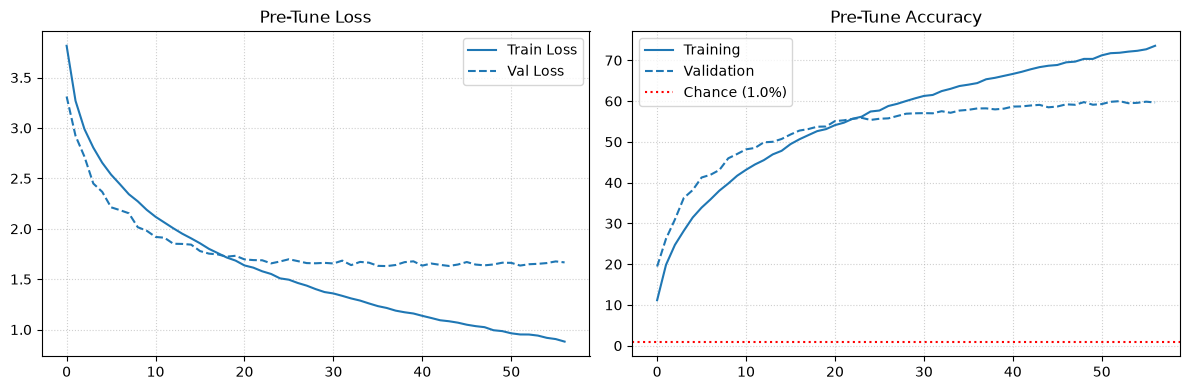


Final Pre-Tune Test Acc: 58.92% (Loss: 1.5774)


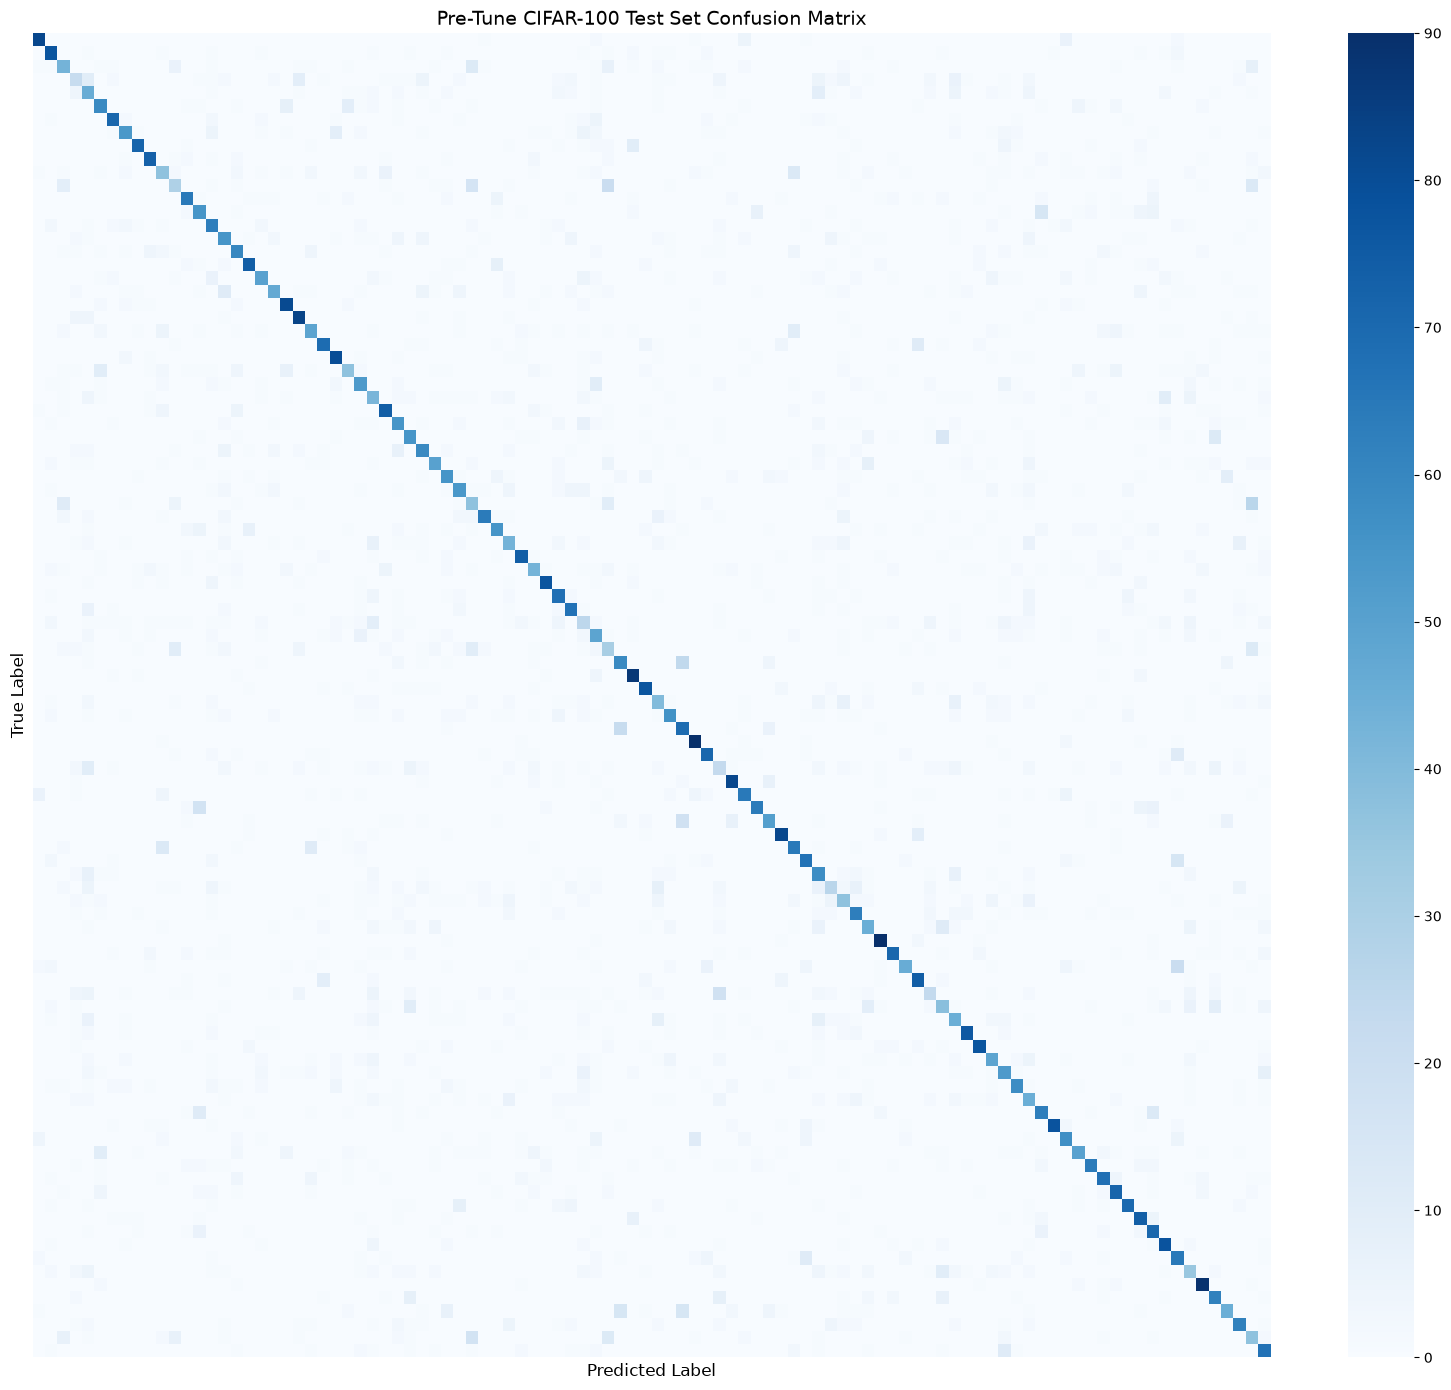


Pre-Tune Total Misclassified Samples: 4108 / 10000


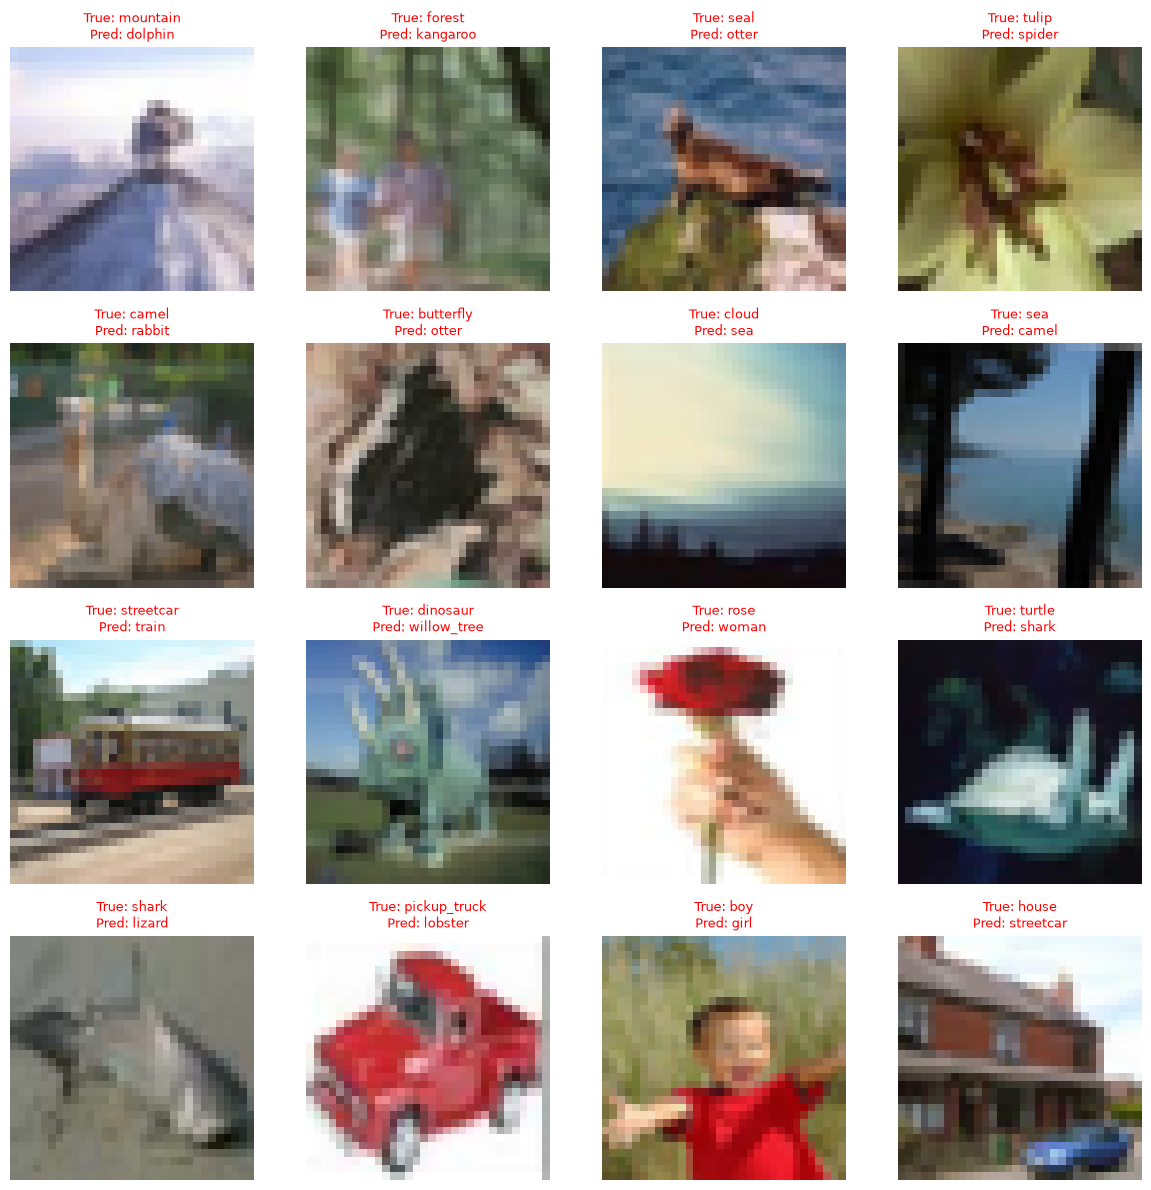

In [7]:
baseline_ckpt = os.path.join(CKPT_DIR, "cnn_baseline.pt")
baseline_model = make_cnn(BASELINE["dropout_rate"])

if os.path.exists(baseline_ckpt):
    print(f"Found checkpoint: loading {baseline_ckpt}")
    base_history = load_run(baseline_ckpt, baseline_model)
else:
    print("No checkpoint found: training the pre-tune model")
    base_history = fit(
        baseline_model, lr=BASELINE["lr"], weight_decay=BASELINE["weight_decay"],
        batch_size=BASELINE["batch_size"], epochs=EPOCHS, patience=PATIENCE, desc="Pre-tune",
    )
    save_run(baseline_ckpt, baseline_model, base_history)

plot_curves(base_history, "Pre-Tune")
pre_tune_test_loss, pre_tune_test_acc, pre_preds = evaluate_gpu(baseline_model, X_test, y_test, return_preds=True)
print(f"\nFinal Pre-Tune Test Acc: {pre_tune_test_acc:.2f}% (Loss: {pre_tune_test_loss:.4f})")
plot_diagnostics(pre_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="Pre-Tune")

## Logistic-regression baseline

Logistic regression: 100%|██████████| 100/100 [01:23<00:00,  1.19epoch/s, tr_loss=3.899, val_acc=12.35%, val_loss=4.234]


Final Logistic Regression Test Acc: 12.20% (Loss: 4.2881)


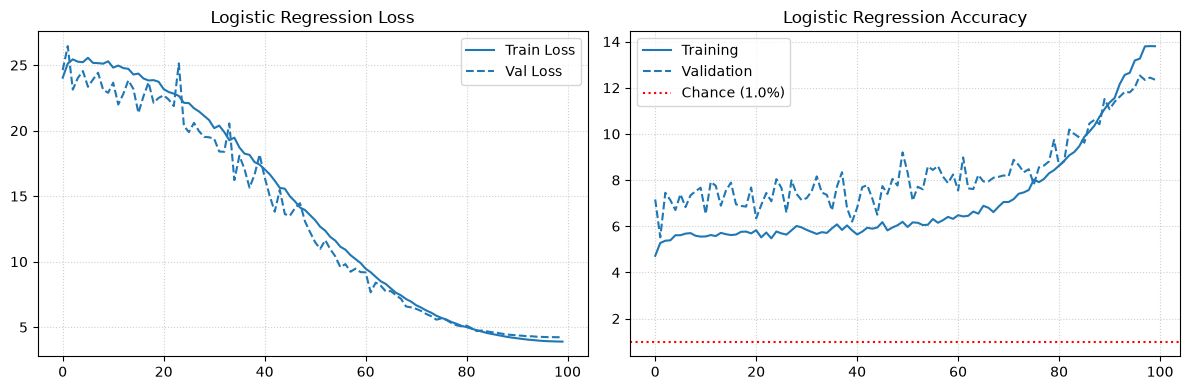

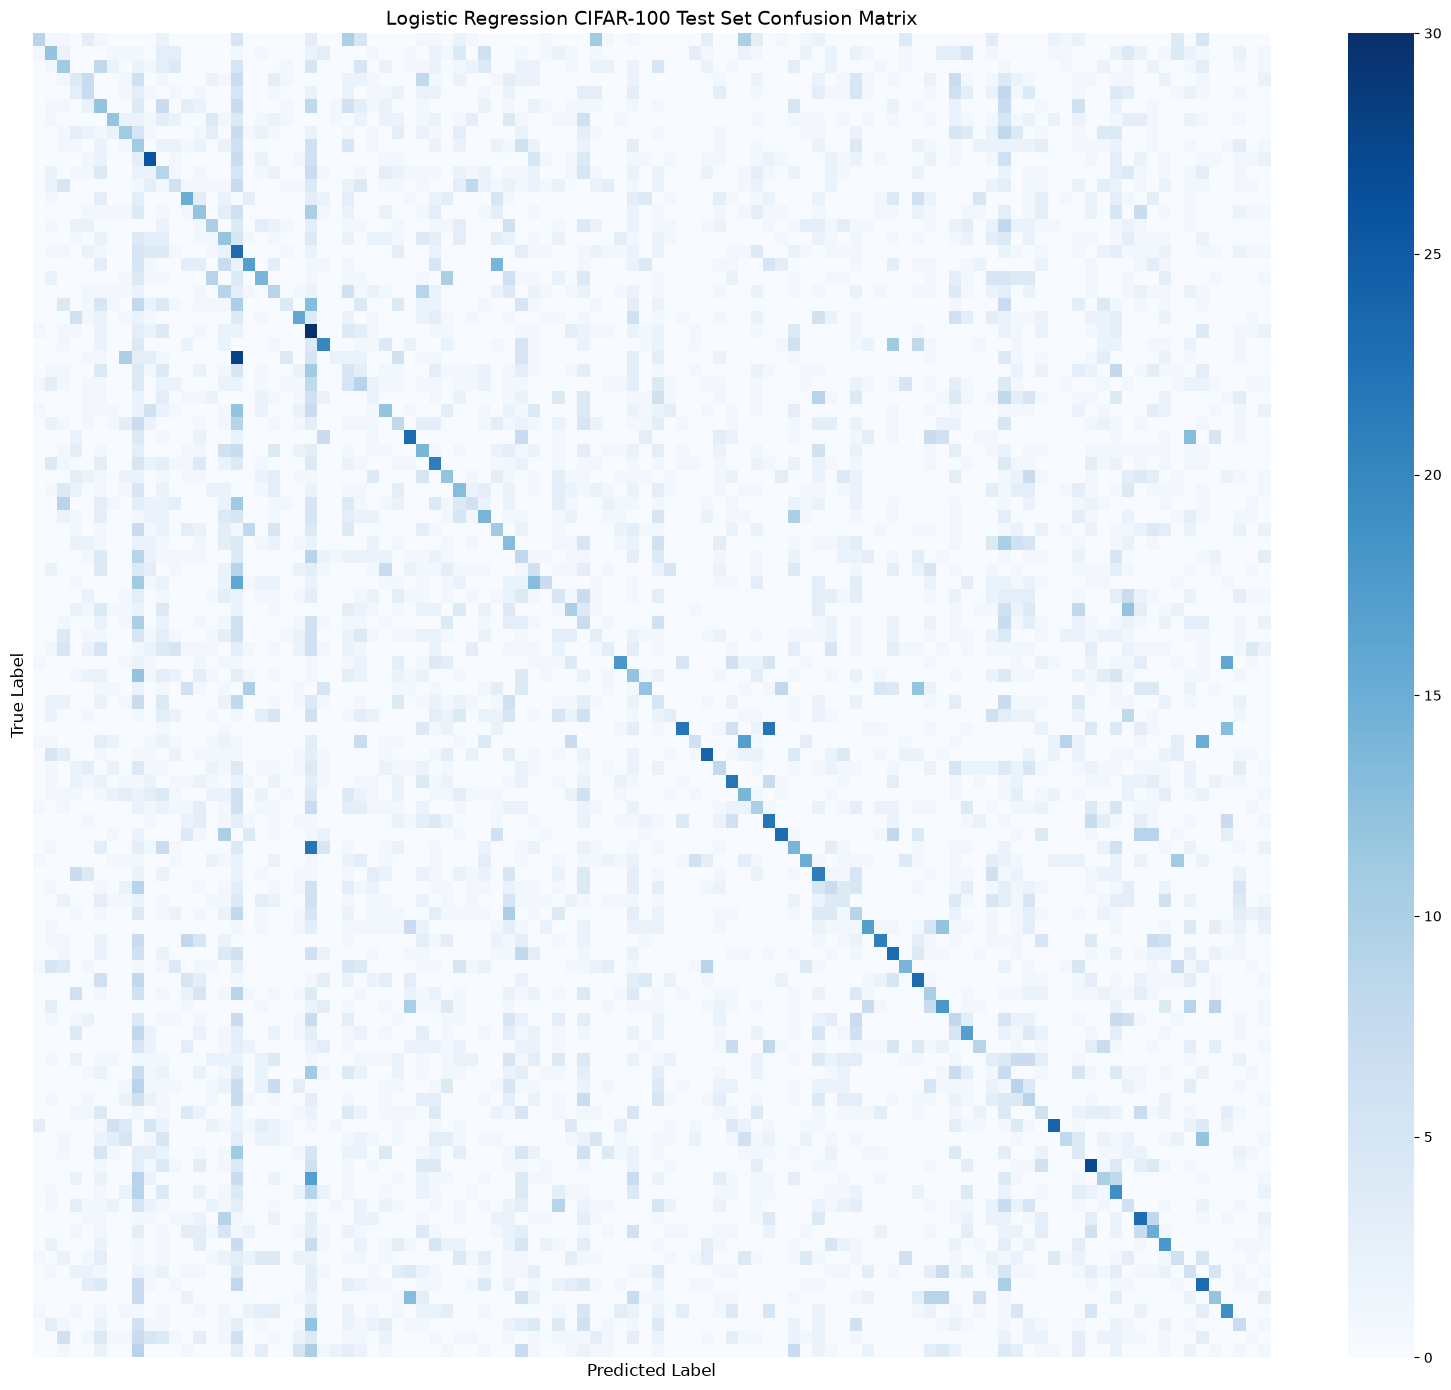


Logistic Regression Total Misclassified Samples: 8780 / 10000


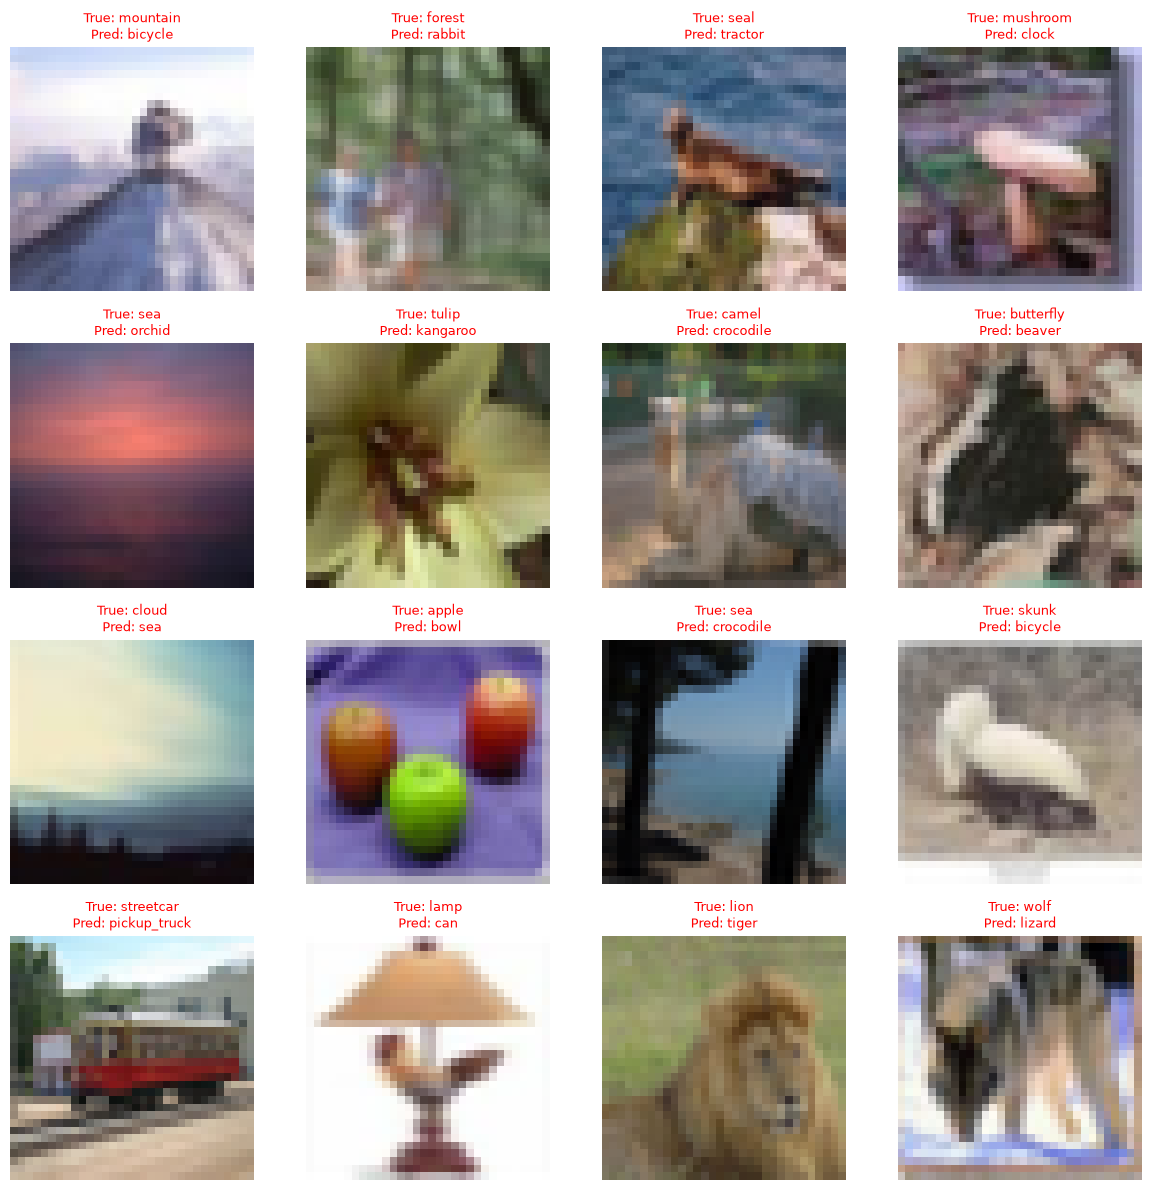

In [8]:
lr_baseline = make_logreg()
lr_history = fit(
    lr_baseline, lr=LOGREG["lr"], weight_decay=LOGREG["weight_decay"],
    batch_size=LOGREG["batch_size"], epochs=EPOCHS, patience=PATIENCE, desc="Logistic regression",
)
lr_test_loss, lr_test_acc, lr_preds = evaluate_gpu(lr_baseline, X_test, y_test, return_preds=True)
print(f"\nFinal Logistic Regression Test Acc: {lr_test_acc:.2f}% (Loss: {lr_test_loss:.4f})")

plot_curves(lr_history, "Logistic Regression")
plot_diagnostics(lr_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="Logistic Regression")

## Optuna search

In [9]:
def objective(trial):
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    dropout_rate = trial.suggest_float("dropout_rate", 0.2, 0.6, step=0.1)
    weight_decay = trial.suggest_float("weight_decay", 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", BATCH_SIZES)

    model = make_cnn(dropout_rate)
    try:
        history = fit(
            model, lr=lr, weight_decay=weight_decay, batch_size=batch_size,
            epochs=N_EPOCHS, trial=trial, verbose=False,   
        )
    finally:
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()                        
    return history["val_acc"][-1]


pbar = tqdm(total=N_TRIALS, desc="Optuna Optimization Progress")


def tqdm_callback(study, trial):
    pbar.update(1)
    try:
        best = f"{study.best_value:.2f}%"  
    except ValueError:
        best = "N/A"
    pbar.set_postfix(best_acc=best)


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.HyperbandPruner(min_resource=1, max_resource=N_EPOCHS, reduction_factor=3))

try:
    study.optimize(objective, n_trials=N_TRIALS, callbacks=[tqdm_callback])
finally:
    pbar.close()

best_params = study.best_params
print(f"Best val accuracy: {study.best_value:.2f}%")
print("Best hyperparameters:")
for key, value in best_params.items():
    print(f"  {key}: {value}")

Optuna Optimization Progress: 100%|██████████| 50/50 [52:20<00:00, 62.81s/it, best_acc=55.34%]  

Best val accuracy: 55.34%
Best hyperparameters:
  lr: 0.00027559086171323477
  dropout_rate: 0.2
  weight_decay: 0.0017148691719973323
  batch_size: 64


## Final tuned model (same pipeline, same epoch budget and patience as the baseline)

Tuned:  89%|████████▉ | 89/100 [09:17<01:08,  6.26s/epoch, tr_loss=0.603, val_acc=61.71%, val_loss=1.526]


Early stopping at epoch 90 (best val loss 1.5171).


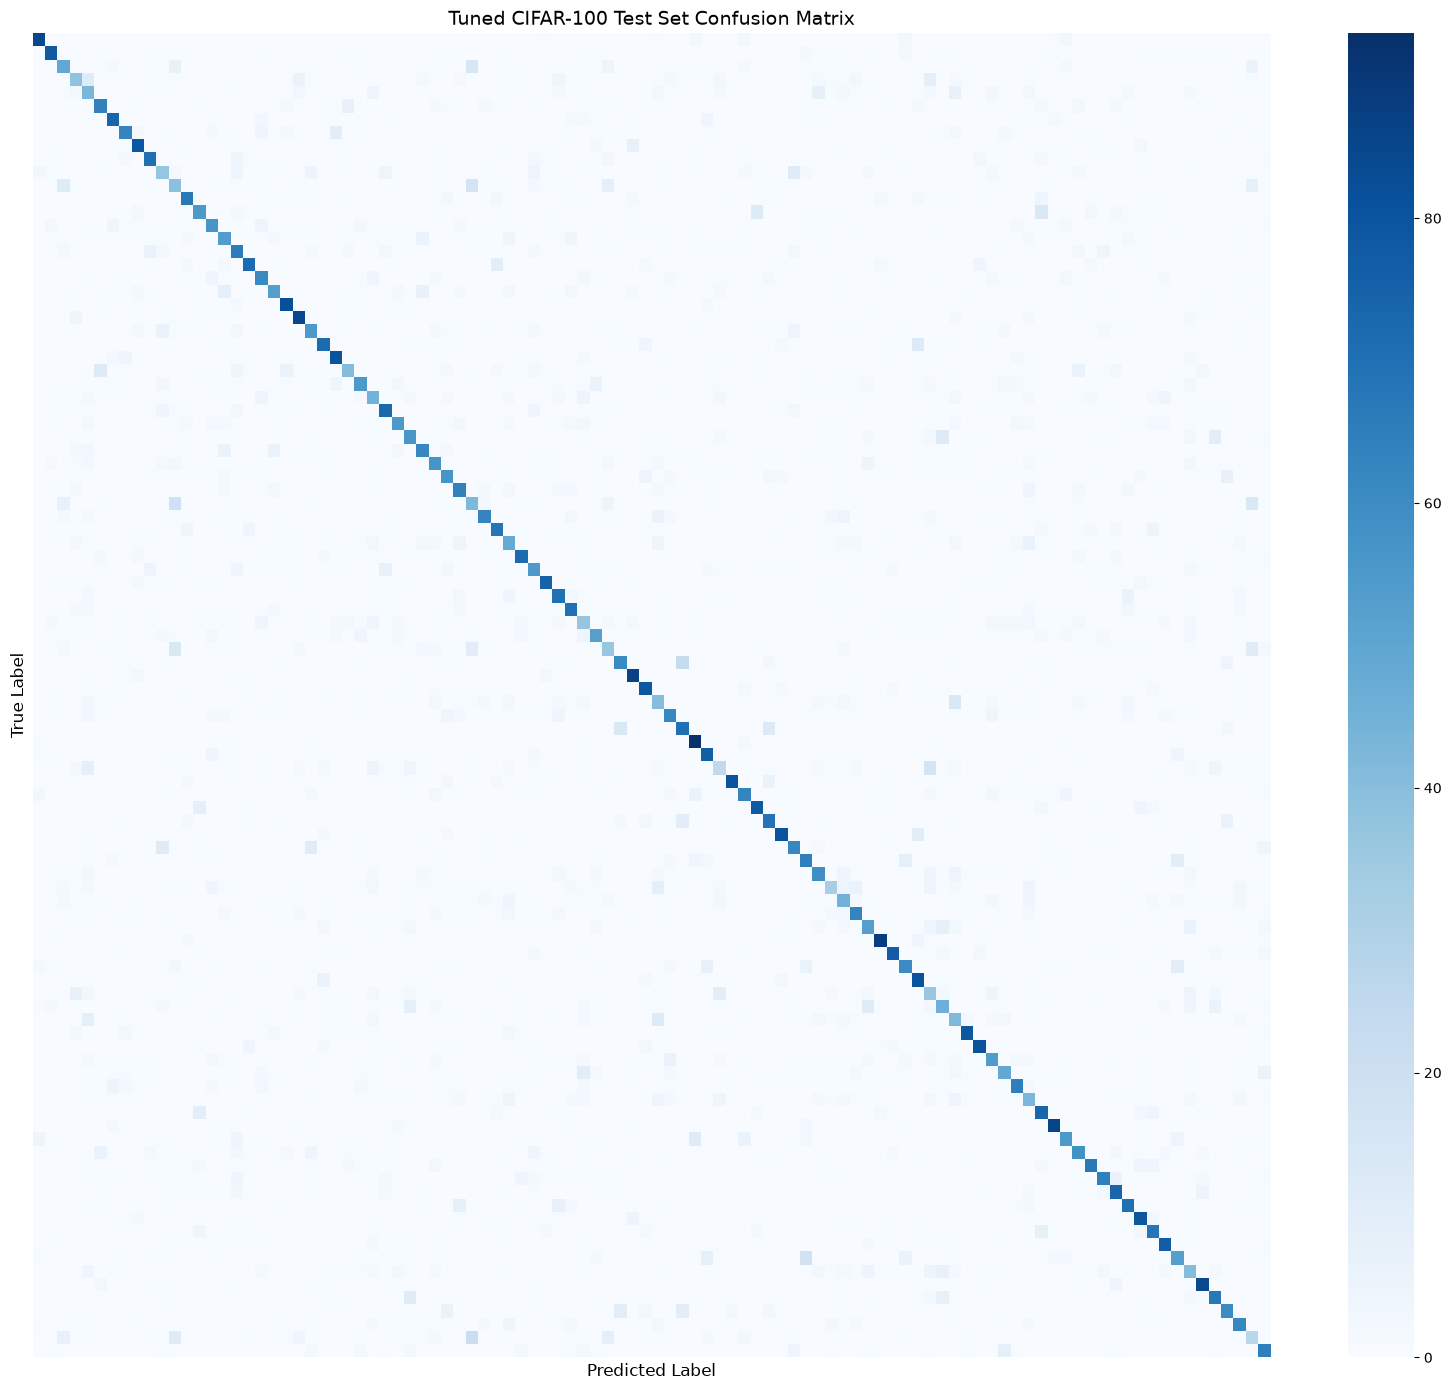


Tuned Total Misclassified Samples: 3795 / 10000


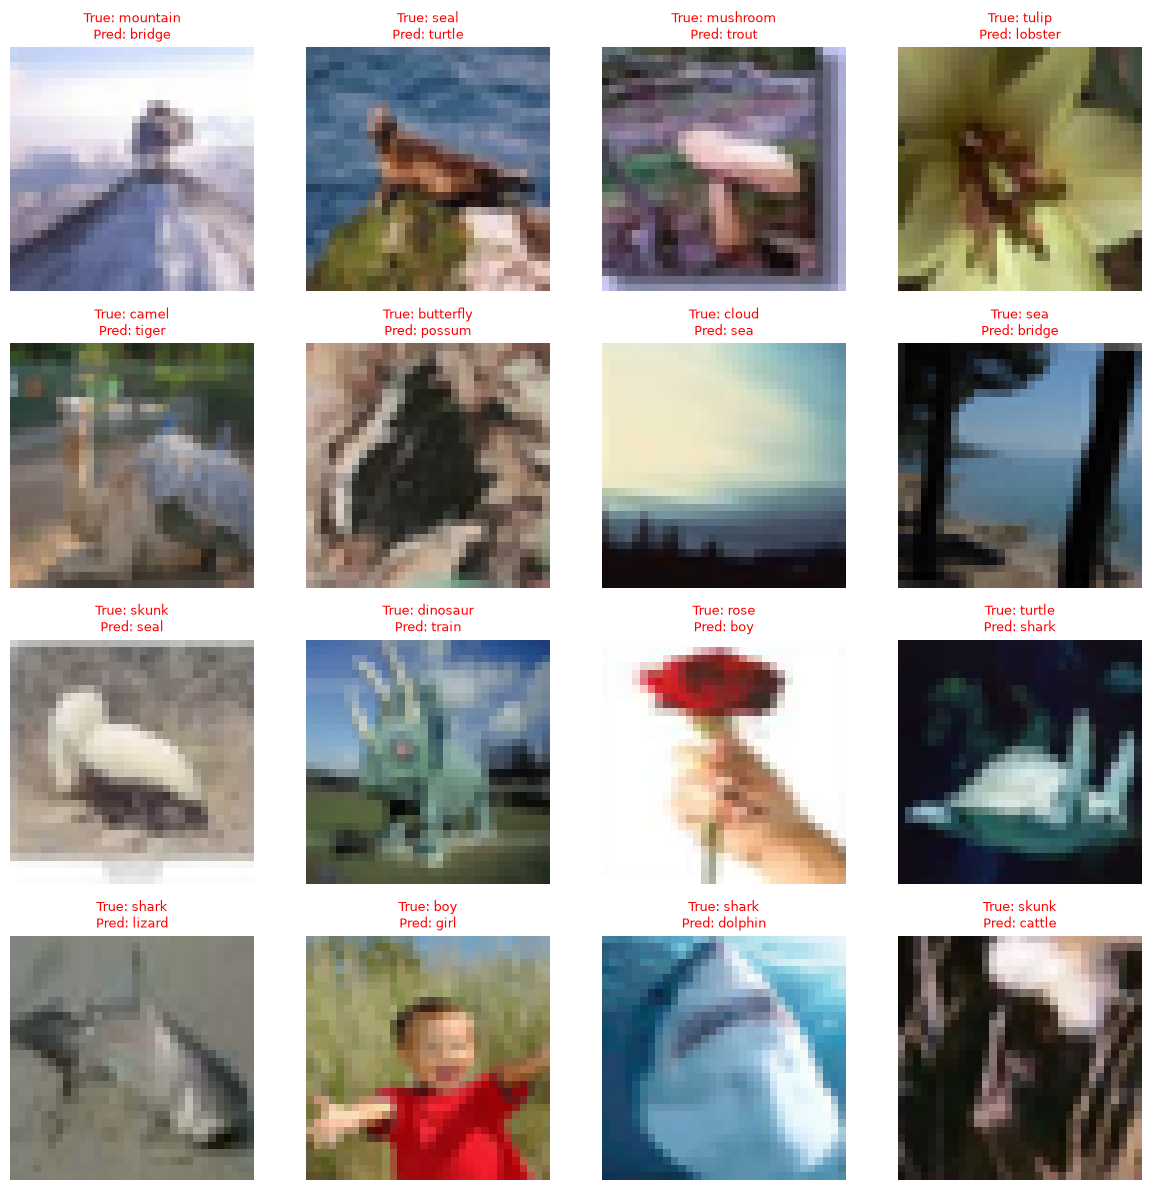

In [10]:
tuned_ckpt = os.path.join(CKPT_DIR, "tuned.pt")
tuned_model = make_cnn(best_params["dropout_rate"])
tuned_history = fit(
    tuned_model, lr=best_params["lr"], weight_decay=best_params["weight_decay"],
    batch_size=best_params["batch_size"], epochs=EPOCHS, patience=PATIENCE, desc="Tuned",
)
save_run(tuned_ckpt, tuned_model, tuned_history)

test_loss, test_acc, tuned_preds = evaluate_gpu(tuned_model, X_test, y_test, return_preds=True)
plot_diagnostics(tuned_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="Tuned")

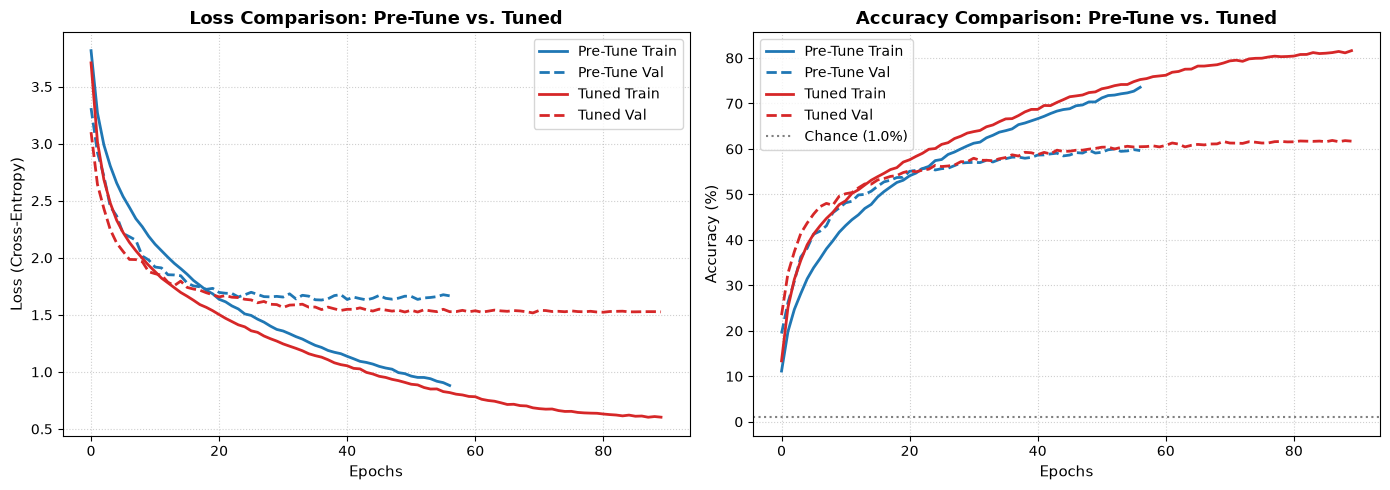


--- Model Performance Comparison ---
Chance accuracy:        1.00%
Logistic regression:    12.20% (Loss: 4.2881)
Before tuning (CNN):    58.92% (Loss: 1.5774)
After tuning (CNN):     62.05% (Loss: 1.4978)
Accuracy difference:    +3.13%


In [11]:
plot_comparison_curves(base_history, tuned_history)

print("\n--- Model Performance Comparison ---")
print(f"Chance accuracy:        {DUMMY_ACC:.2f}%")
print(f"Logistic regression:    {lr_test_acc:.2f}% (Loss: {lr_test_loss:.4f})")
print(f"Before tuning (CNN):    {pre_tune_test_acc:.2f}% (Loss: {pre_tune_test_loss:.4f})")
print(f"After tuning (CNN):     {test_acc:.2f}% (Loss: {test_loss:.4f})")
print(f"Accuracy difference:    {test_acc - pre_tune_test_acc:+.2f}%")